# Mach-Zehnder Interferometer on a Chip

A **directional coupler** is the beam splitter of integrated photonics: two waveguides run close together, and light leaks from one into the other. A coupler that sends half of the power into each output is the on-chip version of a 50:50 beam splitter. Two such couplers joined by two waveguide arms form a **Mach-Zehnder interferometer (MZI)**. MZIs with tunable arms are the unit cell of programmable photonic circuits, including photonic quantum processors [3].

In this challenge you first optimize a directional coupler towards a 50:50 split at 1550 nm. Then you use two copies of it to build an MZI, and choose the arm length difference so that all light leaves through one output port. The quality of the MZI is measured by its **extinction ratio**, and the extinction ratio is limited by how close the coupler is to 50:50.

This notebook gives you a working design. It shows how to:

- compute the guided mode of a silicon waveguide,
- estimate the coupling length of a directional coupler from the modes of the coupled waveguides,
- simulate the coupler with the finite-difference time-domain (FDTD) method,
- assemble and simulate the MZI as a circuit,
- score the design against the challenge constraints.

You change four parameters: the waveguide width, the coupler gap, the coupling length and the arm length difference $\Delta L$.

**References**

1. Chrostowski, L., and Hochberg, M. *Silicon Photonics Design: From Devices to Systems*. Cambridge University Press, 2015, doi: [10.1017/CBO9781316084168](https://doi.org/10.1017/CBO9781316084168).
2. Yariv, A. "Coupled-mode theory for guided-wave optics." *IEEE Journal of Quantum Electronics* 1973 9 (9), 919-933, doi: [10.1109/JQE.1973.1077767](https://doi.org/10.1109/JQE.1973.1077767).
3. Carolan, J., *et al*. "Universal linear optics." *Science* 2015 349 (6249), 711-716, doi: [10.1126/science.aab3642](https://doi.org/10.1126/science.aab3642).

## Physics primer

**Waveguide modes.** A silicon strip waveguide (refractive index about 3.48) surrounded by silica (about 1.44) guides light by total internal reflection. Each guided mode travels with an **effective index** $n_{eff}$: its phase advances by $2\pi n_{eff} L / \lambda$ over a length $L$ at the vacuum wavelength $\lambda$.

**Directional coupler.** When two identical waveguides are placed a small gap apart, their modes overlap and combine into two **supermodes** of the pair: an even one, with the field in phase in both guides, and an odd one, with opposite signs [2]. The two supermodes travel with slightly different effective indices, $n_{even}$ and $n_{odd}$. Light launched into one waveguide excites both supermodes equally, and as they drift out of phase the power moves into the other waveguide. After a length $L$ the fraction of power in the other waveguide (the **cross port**) is

$$P_{cross} = \sin^2\left(\frac{\pi\,\Delta n\,L}{\lambda}\right), \qquad \Delta n = n_{even} - n_{odd}.$$

A 50:50 split needs $\pi \Delta n L / \lambda = \pi/4$, so the required straight coupling length is

$$L_{50} = \frac{\lambda}{4\,\Delta n}.$$

The S-bends that bring the waveguides together and apart also couple some light, because the gap there is still small. The real straight section is therefore shorter than $L_{50}$.

**Design levers.** The evanescent field decays exponentially outside the core, so $\Delta n$ falls roughly exponentially as the gap grows. A narrower waveguide confines the mode less, which spreads the field further into the gap and increases $\Delta n$. Because $\Delta n$ and $\lambda$ both change with wavelength, the split also drifts across the band, which is what the stretch goal measures.

**Mach-Zehnder interferometer.** The first coupler splits the input between two arms. The arms differ in length by $\Delta L$, which adds a phase difference

$$\Delta\varphi = \frac{2\pi\,n_{eff}\,\Delta L}{\lambda}.$$

The second coupler recombines the two beams. With ideal 50:50 couplers the power in the bright output is

$$P_{out} = \cos^2\left(\frac{\Delta\varphi}{2}\right),$$

so all light exits one port when $\Delta\varphi$ is a whole multiple of $2\pi$. With $\Delta L = 0$ that port is the cross port of the MZI.

**Extinction ratio.** If the couplers send a fraction $k$ to the cross port instead of exactly one half, the two paths no longer cancel perfectly in the dark port. For $\Delta\varphi = 2\pi m$ the dark port receives $(1 - 2k)^2$ of the power, and the **extinction ratio**, the ratio of bright to dark output power, is

$$ER = 10 \log_{10}\frac{4k(1-k)}{(1 - 2k)^2}\ \text{dB}.$$

For example, $k = 0.49$ gives 34 dB, and $k = 0.495$ gives 40 dB, the cap of the score.

## Imports

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import photonforge as pf
import tidy3d as td
from photonforge.live_viewer import LiveViewer

# Start the interactive layout viewer
viewer = LiveViewer()

# We raise the Tidy3D logging level to reduce output noise from the
# simulations below. Warnings can flag real problems, so only suppress them
# once you have confirmed they are not relevant to your case.
td.config.logging.level = "ERROR"

LiveViewer started at http://127.0.0.1:64519. Call its 'stop()' method to free the port.


## Design parameters

These four values are the design. Keep each one inside its range. The starting values give a working coupler and MZI, but the coupler is far from 50:50, so the starting score is zero.

In [3]:
# Width of the silicon waveguides, allowed range 0.40 to 0.55 (μm)
width = 0.5

# Gap between the two waveguides in the coupler, allowed range 0.10 to 0.40 (μm)
gap = 0.2

# Length of the straight coupling section, allowed range 0 to 30 (μm)
coupling_length = 14.88

# Arm length difference of the MZI, allowed range 0 to 100 (μm)
delta_length = 15 * 0.63522

The rest of the layout is fixed. The S-bends of the coupler are 10 µm long and move each waveguide 2 µm sideways. The two couplers of the MZI sit 150 µm apart, and the MZI arms use a 10 µm bend radius. The simulations cover the telecom C band, 1530 to 1565 nm, in 1 nm steps.

In [4]:
s_bend_length = 10.0  # Length of each coupler S-bend (μm)
s_bend_offset = 2.0  # Lateral offset of each coupler S-bend (μm)
arm_length = 150.0  # Distance between the two couplers of the MZI (μm)
arm_radius = 10.0  # Bend radius of the MZI arms (μm)

# Wavelengths of the simulations (μm) and the corresponding frequencies (Hz)
wavelengths = np.linspace(1.530, 1.565, 36)
frequencies = pf.C_0 / wavelengths

# Index of the 1550 nm design wavelength
i_1550 = np.argmin(np.abs(wavelengths - 1.550))

## Technology and waveguide mode

PhotonForge's built-in [basic technology](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.basic_technology.html) is a silicon-on-insulator platform: a 220 nm silicon layer on a 2 µm buried oxide, covered by silica. Its `"Strip"` port specification describes a strip waveguide, and the `strip_width` argument sets the waveguide width used everywhere below.

In [5]:
# Silicon-on-insulator technology with the chosen waveguide width
technology = pf.basic_technology(strip_width=width)
pf.config.default_technology = technology

# Port specification of the strip waveguide
strip = technology.ports["Strip"]
strip

PortSpec(description="Strip waveguide", width=2.25, limits=(-1, 1.22), num_modes=1, added_solver_modes=0, polarization="", target_neff=0, default_radius=0, path_profiles=[(0.5, 0, (2, 0)), (2.5, 0, (1, 0))])

The next cell solves for the fundamental transverse-electric (TE) mode of the strip waveguide across the band. The effective index sets the phase of the MZI arms. The group index $n_g$ sets the free spectral range of the MZI, the wavelength spacing between its transmission peaks, $\lambda^2 / (n_g \Delta L)$.

22:21:50 EST Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=7194603;https://tidy3d.simulation.cloud/workbench?taskId=mo-9285193c-16d4-4af5-9602-779d52037123\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=7194604;https://tidy3d.simulation.cloud/workbench?taskId=mo-9285193c-16d4-4af5-9602-779d52037123\taskId]8;;\]8;id=7194603;https://tidy3d.simulation.cloud/workbench?taskId=mo-9285193c-16d4-4af5-9602-779d52037123\=]8;;\]8;id=7194605;https://tidy3d.simulation.cloud/workbench?taskId=mo-9285193c-16d4-4af5-9602-779d52037123\mo]8;;\]8;id=7194603;https://tidy3d.simulation.cloud/workbench?taskId=mo-9285193c-16d4-4af5-9602-779d52037123\-9285193c-16d4-]8;;\
             ]8;id=7194603;https://tidy3d.simulation.cloud/workbench?taskId=mo-9285193c-16d4-4af5-9602-779d52037123\4af5-9602-779d52037123']8;;\.

Progress: 100% 
Effective index at 1550 nm: 2.4401
Group index at 1550 nm: 4.1811


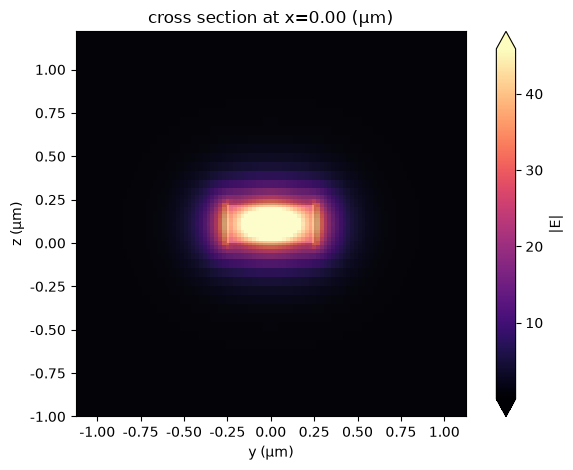

In [6]:
# Solve for the strip waveguide mode across the band
strip_modes = pf.port_modes("Strip", frequencies, group_index=True)

# Effective and group indices at 1550 nm
n_eff = strip_modes.data.n_eff.isel(mode_index=0).values[i_1550]
n_group = strip_modes.data.n_group.isel(mode_index=0).values[i_1550]
print(f"Effective index at 1550 nm: {n_eff:.4f}")
print(f"Group index at 1550 nm: {n_group:.4f}")

# Field magnitude of the mode at 1550 nm
_ = strip_modes.plot_field("E", "abs", mode_index=0, f=frequencies[i_1550])

## Coupling length estimate

The supermodes of the coupler come from a mode solve of a cross-section with both waveguides, a distance `width + gap` apart. This port specification is built only for the estimate, with two modes and the starting guess of the solver set to the silicon index. The estimate costs one mode solve, so it is a cheap way to explore the gap and width before you spend an FDTD run.

In [7]:
# Distance between the two waveguide centres in the coupler (μm)
coupling_distance = width + gap

# Cross-section with both waveguides and the silica cladding around them
coupled_strips = pf.PortSpec(
    description="Coupled strips",
    width=strip.width + coupling_distance,
    limits=strip.limits,
    num_modes=2,
    target_neff=3.5,
    path_profiles=[
        (width, coupling_distance / 2, "WG_CORE"),
        (width, -coupling_distance / 2, "WG_CORE"),
        (strip.path_profiles[1][0] + coupling_distance, 0, "WG_CLAD"),
    ],
)

# Solve for the even and odd supermodes at 1550 nm
supermodes = pf.port_modes(coupled_strips, [frequencies[i_1550]])
n_even, n_odd = supermodes.data.n_eff.values.ravel()

# Straight coupling length for a 50:50 split, without the S-bends (μm)
l_50 = 1.550 / (4 * (n_even - n_odd))
print(f"Supermode indices: {n_even:.6f} (even), {n_odd:.6f} (odd)")
print(f"Estimated 50:50 coupling length without the S-bends: {l_50:.3f} μm")
print(f"Estimated 50:50 coupling length with the S-bends: {l_50 - 2.26:.3f} μm")


22:21:54 EST Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=7194609;https://tidy3d.simulation.cloud/workbench?taskId=mo-b5b0dcef-10c4-43b2-ae42-4fe5da590931\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=7194610;https://tidy3d.simulation.cloud/workbench?taskId=mo-b5b0dcef-10c4-43b2-ae42-4fe5da590931\taskId]8;;\]8;id=7194609;https://tidy3d.simulation.cloud/workbench?taskId=mo-b5b0dcef-10c4-43b2-ae42-4fe5da590931\=]8;;\]8;id=7194611;https://tidy3d.simulation.cloud/workbench?taskId=mo-b5b0dcef-10c4-43b2-ae42-4fe5da590931\mo]8;;\]8;id=7194609;https://tidy3d.simulation.cloud/workbench?taskId=mo-b5b0dcef-10c4-43b2-ae42-4fe5da590931\-b5b0dcef-10c4-]8;;\
             ]8;id=7194609;https://tidy3d.simulation.cloud/workbench?taskId=mo-b5b0dcef-10c4-43b2-ae42-4fe5da590931\43b2-ae42-4fe5da590931']8;;\.

Progress: 100% 
Supermode indices: 2.450733 (even), 2.429554 (odd)
Estimated 50:50 coupling length without the S-bends: 18.296 μm
Estimated 50:50 coupling length with the S-bends: 16.036 μm


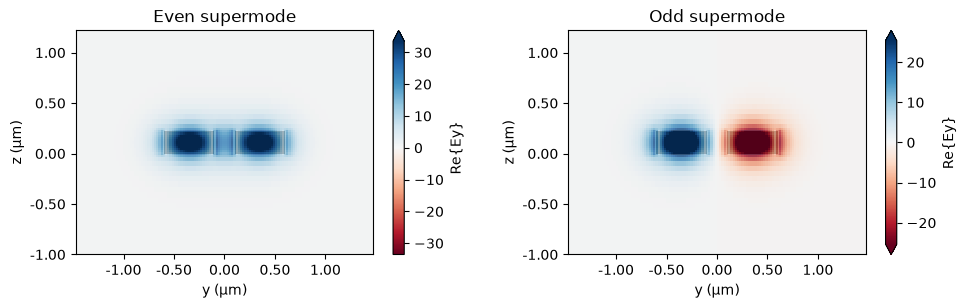

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3), tight_layout=True)

# Lateral field component of the even and odd supermodes
for m, name in enumerate(("Even", "Odd")):
    supermodes.plot_field("Ey", "real", mode_index=m, f=frequencies[i_1550], ax=ax[m])
    ax[m].set_title(f"{name} supermode")
plt.show()

## Directional coupler

The coupler is PhotonForge's [s_bend_coupler](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.parametric.s_bend_coupler.html): two S-bends bring the waveguides to the gap, a straight section couples them, and two more S-bends separate them again. Its ports are:

- `P0`, bottom left, the input,
- `P1`, top left,
- `P2`, bottom right, the **through** port,
- `P3`, top right, the **cross** port.

The coupler is simulated with a [Tidy3DModel](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.Tidy3DModel.html), which runs 3D FDTD. The coupler is mirror symmetric left to right and top to bottom, so every column of its scattering matrix follows from the single run with light entering `P0`. The `port_symmetries` argument lists these port swaps. The mesh uses 12 cells per wavelength (`grid_spec=12`), which keeps one run to about a minute.

Each S-bend is made of two circular arcs. For an S-bend of length $L_s$ and offset $H$, their radius is

$$R = \frac{L_s^2 + H^2}{4H}.$$

In [9]:
@pf.parametric_component
def directional_coupler(
    *,
    gap: float = 0.2,
    coupling_length: float = 5.0,
    s_bend_length: float = 10.0,
    s_bend_offset: float = 2.0,
):
    # Waveguide width taken from the strip port specification (μm)
    core_width = pf.config.default_technology.ports["Strip"].path_profiles[0][0]
    print(core_width)

    # Port swaps under the left-right, top-bottom and combined mirror symmetries
    port_symmetries = [
        ("P1", "P0", "P3", "P2"),
        ("P2", "P3", "P0", "P1"),
        ("P3", "P2", "P1", "P0"),
    ]

    # S-bend coupler simulated with FDTD
    return pf.parametric.s_bend_coupler(
        port_spec="Strip",
        coupling_distance=core_width + gap,
        s_bend_length=s_bend_length,
        s_bend_offset=s_bend_offset,
        coupling_length=coupling_length,
        model=pf.Tidy3DModel(port_symmetries=port_symmetries, grid_spec=12),
    )


# Build the coupler for the current design parameters
coupler = directional_coupler(
    gap=gap,
    coupling_length=coupling_length,
    s_bend_length=s_bend_length,
    s_bend_offset=s_bend_offset,
)
viewer(coupler)

0.5


In [17]:
# Radius of the circular arcs in the coupler S-bends (μm)
s_bend_radius = (s_bend_length**2 + s_bend_offset**2) / (4 * s_bend_offset)
print(f"S-bend radius: {s_bend_radius:.1f} μm")

S-bend radius: 13.0 μm


The next cell builds the FDTD simulation without running it, plots it from the top and from the side, and asks the server for the cost of the run. Check the cost against your team's budget before you run.

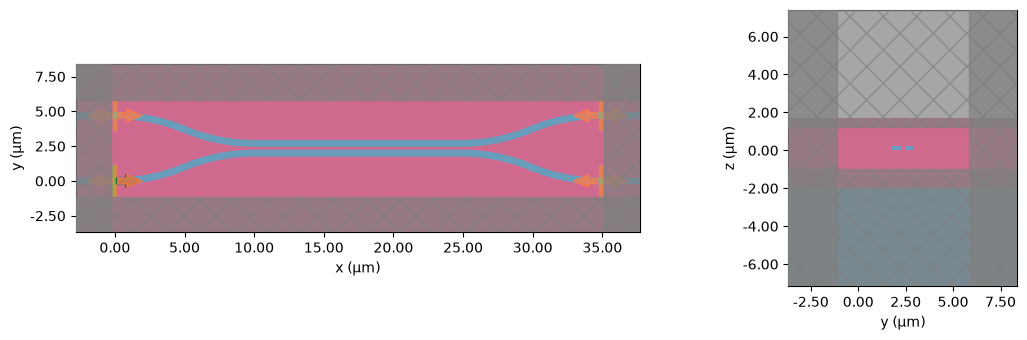

22:22:02 EST Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=7194615;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0beeb26f-bf71-4334-829b-2f61361f4b62\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=7194616;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0beeb26f-bf71-4334-829b-2f61361f4b62\taskId]8;;\]8;id=7194615;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0beeb26f-bf71-4334-829b-2f61361f4b62\=]8;;\]8;id=7194617;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0beeb26f-bf71-4334-829b-2f61361f4b62\fdve]8;;\]8;id=7194615;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0beeb26f-bf71-4334-829b-2f61361f4b62\-0beeb26f-bf7]8;;\
             ]8;id=7194615;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0beeb26f-bf71-4334-829b-2f61361f4b62\1-4334-829b-2f61361f4b62']8;;\.

In [10]:
# FDTD simulation with light entering P0
simulation = coupler.active_model.get_simulations(coupler, frequencies)["P0@0"]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), tight_layout=True)

# Top view through the middle of the silicon layer
simulation.plot(z=0.11, ax=ax[0])

# Side view through the middle of the coupling section
simulation.plot(x=simulation.center[0], ax=ax[1])
for a in ax:
    a.set_title("")
plt.show()

# Maximum cost of the run in FlexCredits
cost = coupler.active_model.estimate_cost(coupler, frequencies)

The next cell submits the FDTD run and waits for it. PhotonForge caches the result, so running the cell again with the same design costs nothing.

In [11]:
# Scattering matrix of the coupler from one FDTD run
s_coupler = coupler.s_matrix(frequencies)

22:22:21 EST Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=7194620;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0beeb26f-bf71-4334-829b-2f61361f4b62\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=7194621;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0beeb26f-bf71-4334-829b-2f61361f4b62\taskId]8;;\]8;id=7194620;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0beeb26f-bf71-4334-829b-2f61361f4b62\=]8;;\]8;id=7194622;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0beeb26f-bf71-4334-829b-2f61361f4b62\fdve]8;;\]8;id=7194620;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0beeb26f-bf71-4334-829b-2f61361f4b62\-0beeb26f-bf7]8;;\
             ]8;id=7194620;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0beeb26f-bf71-4334-829b-2f61361f4b62\1-4334-829b-2f61361f4b62']8;;\.

Progress: 100% 


Through power at 1550 nm: 0.4977
Cross power at 1550 nm: 0.4977
Excess loss at 1550 nm: 0.020 dB
Split ratio at 1550 nm: 50.00 %


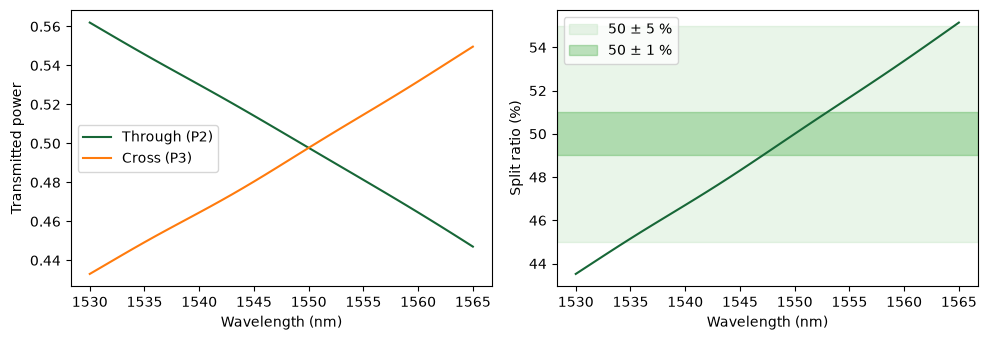

SLOPE
0.32968629468565147
11.539020313997801


In [12]:
# Power in the through and cross ports for light entering P0
through = np.abs(s_coupler["P0@0", "P2@0"]) ** 2
cross = np.abs(s_coupler["P0@0", "P3@0"]) ** 2

# Split ratio: share of the output power in the cross port (%)
split = 100 * cross / (through + cross)

print(f"Through power at 1550 nm: {through[i_1550]:.4f}")
print(f"Cross power at 1550 nm: {cross[i_1550]:.4f}")
print(
    f"Excess loss at 1550 nm: {-10 * np.log10(through[i_1550] + cross[i_1550]):.3f} dB"
)
print(f"Split ratio at 1550 nm: {split[i_1550]:.2f} %")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), tight_layout=True)

# Through and cross power across the band
ax[0].plot(wavelengths * 1e3, through, label="Through (P2)")
ax[0].plot(wavelengths * 1e3, cross, label="Cross (P3)")
ax[0].set_xlabel("Wavelength (nm)")
ax[0].set_ylabel("Transmitted power")
ax[0].legend()

# Split ratio across the band with the 50 ± 1 % and 50 ± 5 % windows
ax[1].plot(wavelengths * 1e3, split)
ax[1].axhspan(45, 55, color="tab:green", alpha=0.1, label="50 ± 5 %")
ax[1].axhspan(49, 51, color="tab:green", alpha=0.3, label="50 ± 1 %")
ax[1].set_xlabel("Wavelength (nm)")
ax[1].set_ylabel("Split ratio (%)")
ax[1].legend()
plt.show()

print("SLOPE")
slope = (split[1] - split[0])/(wavelengths[1] - wavelengths[0]) * (1/1000)
print(slope)
print(slope * (1565 - 1530))

## Mach-Zehnder interferometer

The MZI places two copies of the coupler 150 µm apart and joins them with two arms. Both arms are drawn in a single call to [route_auto](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.parametric.route_auto.html), PhotonForge's automatic router.

The arm length difference is stated as a target rather than drawn by hand. A [PathLengthMatching](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.PathLengthMatching.html) group tells the router to equalize `offset + routed length` over the arms. Crediting the lower arm with an offset of $\Delta L$ therefore makes the router lengthen the upper arm by exactly $\Delta L$, which it does by inserting a meander of bends. The meander bends use the same 10 µm radius as the rest of the route.

The routed waveguides use waveguide models that take the effective index from a mode solve of the strip and the length from the layout. A [CircuitModel](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.CircuitModel.html) then combines the scattering matrices of all parts, including the two copies of the FDTD coupler. The MZI therefore needs no new FDTD run.

0.5


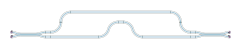

In [13]:
@pf.parametric_component
def mzi(
    *,
    gap: float = 0.2,
    coupling_length: float = 5.0,
    delta_length: float = 10.0,
    s_bend_length: float = 10.0,
    s_bend_offset: float = 2.0,
    arm_length: float = 150.0,
    arm_radius: float = 10.0,
):
    # Create the MZI component
    interferometer = pf.Component("MZI")

    # Coupler used for both the splitter and the combiner
    coupler = directional_coupler(
        gap=gap,
        coupling_length=coupling_length,
        s_bend_length=s_bend_length,
        s_bend_offset=s_bend_offset,
    )

    # Place the splitter at the origin and the combiner one arm length after it
    splitter = interferometer.add_reference(coupler)
    combiner = interferometer.add_reference(coupler)
    combiner.translate((splitter["P2"].center[0] + arm_length, 0))

    # Route both arms, making the upper arm longer than the lower one by delta_length
    arms = pf.parametric.route_auto(
        port1=[(splitter, "P2"), (splitter, "P3")],
        port2=[(combiner, "P0"), (combiner, "P1")],
        radius=arm_radius,
        matching=[pf.PathLengthMatching(offsets=[delta_length, 0.0])],
    )
    interferometer.add_reference(arms)

    # Expose the two inputs and two outputs and simulate the MZI as a circuit
    interferometer.add_port(
        [splitter["P0"], splitter["P1"], combiner["P2"], combiner["P3"]]
    )
    interferometer.add_model(pf.CircuitModel(), "Circuit")
    return interferometer


# Build the MZI for the current design parameters
device = mzi(
    gap=gap,
    coupling_length=coupling_length,
    delta_length=delta_length,
    s_bend_length=s_bend_length,
    s_bend_offset=s_bend_offset,
    arm_length=arm_length,
    arm_radius=arm_radius,
)
viewer(device)

The router reports nothing when it succeeds, so the next cell measures both arms with [route_length](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.route_length.html) and prints the arm length difference it achieved. If a target cannot fit, the router leaves the arms unmatched, and this printout shows it.

In [14]:
# Routed arms inside the MZI, lower arm first
routes = next(
    ref.component for ref in device.references if ref.component.name != coupler.name
)

# Length of each routed arm (μm)
arm_lengths = [pf.route_length(ref.component) for ref in routes.references]

# Arm length difference achieved by the router (μm)
achieved_delta = arm_lengths[1] - arm_lengths[0]
print(f"Arm lengths: {arm_lengths[0]:.4f} μm (lower), {arm_lengths[1]:.4f} μm (upper)")
print(f"Arm length difference: {achieved_delta:.4f} μm (target {delta_length:.4f} μm)")

Arm lengths: 163.9006 μm (lower), 173.4292 μm (upper)
Arm length difference: 9.5286 μm (target 9.5283 μm)


The MZI ports follow the same convention as the coupler: `P0` and `P1` are the inputs on the left, and `P2` (bottom) and `P3` (top) are the outputs on the right. Light enters `P0`.

22:22:32 EST Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=7194626;https://tidy3d.simulation.cloud/workbench?taskId=mo-f94895f6-67dc-402c-be4b-f8a7fddeea7a\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=7194627;https://tidy3d.simulation.cloud/workbench?taskId=mo-f94895f6-67dc-402c-be4b-f8a7fddeea7a\taskId]8;;\]8;id=7194626;https://tidy3d.simulation.cloud/workbench?taskId=mo-f94895f6-67dc-402c-be4b-f8a7fddeea7a\=]8;;\]8;id=7194628;https://tidy3d.simulation.cloud/workbench?taskId=mo-f94895f6-67dc-402c-be4b-f8a7fddeea7a\mo]8;;\]8;id=7194626;https://tidy3d.simulation.cloud/workbench?taskId=mo-f94895f6-67dc-402c-be4b-f8a7fddeea7a\-f94895f6-67dc-]8;;\
             ]8;id=7194626;https://tidy3d.simulation.cloud/workbench?taskId=mo-f94895f6-67dc-402c-be4b-f8a7fddeea7a\402c-be4b-f8a7fddeea7a']8;;\.

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=7194632;https://tidy3d.simulation.cloud/workbench?taskId=mo-a6c8d74c-5934-4d7f-b808-b3f2d0edf44a\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=7194633;https://tidy3d.simulation.cloud/workbench?taskId=mo-a6c8d74c-5934-4d7f-b808-b3f2d0edf44a\taskId]8;;\]8;id=7194632;https://tidy3d.simulation.cloud/workbench?taskId=mo-a6c8d74c-5934-4d7f-b808-b3f2d0edf44a\=]8;;\]8;id=7194634;https://tidy3d.simulation.cloud/workbench?taskId=mo-a6c8d74c-5934-4d7f-b808-b3f2d0edf44a\mo]8;;\]8;id=7194632;https://tidy3d.simulation.cloud/workbench?taskId=mo-a6c8d74c-5934-4d7f-b808-b3f2d0edf44a\-a6c8d74c-5934-]8;;\
             ]8;id=7194632;https://tidy3d.simulation.cloud/workbench?taskId=mo-a6c8d74c-5934-4d7f-b808-b3f2d0edf44a\4d7f-b808-b3f2d0edf44a']8;;\.

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=7194638;https://tidy3d.simulation.cloud/workbench?taskId=mo-652e885a-0ffe-4035-8d3f-030c3f0d86a8\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=7194639;https://tidy3d.simulation.cloud/workbench?taskId=mo-652e885a-0ffe-4035-8d3f-030c3f0d86a8\taskId]8;;\]8;id=7194638;https://tidy3d.simulation.cloud/workbench?taskId=mo-652e885a-0ffe-4035-8d3f-030c3f0d86a8\=]8;;\]8;id=7194640;https://tidy3d.simulation.cloud/workbench?taskId=mo-652e885a-0ffe-4035-8d3f-030c3f0d86a8\mo]8;;\]8;id=7194638;https://tidy3d.simulation.cloud/workbench?taskId=mo-652e885a-0ffe-4035-8d3f-030c3f0d86a8\-652e885a-0ffe-]8;;\
             ]8;id=7194638;https://tidy3d.simulation.cloud/workbench?taskId=mo-652e885a-0ffe-4035-8d3f-030c3f0d86a8\4035-8d3f-030c3f0d86a8']8;;\.

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=7194644;https://tidy3d.simulation.cloud/workbench?taskId=mo-607b0b42-ac6a-432c-a4d8-b7b8fc241457\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=7194645;https://tidy3d.simulation.cloud/workbench?taskId=mo-607b0b42-ac6a-432c-a4d8-b7b8fc241457\taskId]8;;\]8;id=7194644;https://tidy3d.simulation.cloud/workbench?taskId=mo-607b0b42-ac6a-432c-a4d8-b7b8fc241457\=]8;;\]8;id=7194646;https://tidy3d.simulation.cloud/workbench?taskId=mo-607b0b42-ac6a-432c-a4d8-b7b8fc241457\mo]8;;\]8;id=7194644;https://tidy3d.simulation.cloud/workbench?taskId=mo-607b0b42-ac6a-432c-a4d8-b7b8fc241457\-607b0b42-ac6a-]8;;\
             ]8;id=7194644;https://tidy3d.simulation.cloud/workbench?taskId=mo-607b0b42-ac6a-432c-a4d8-b7b8fc241457\432c-a4d8-b7b8fc241457']8;;\.

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=7194650;https://tidy3d.simulation.cloud/workbench?taskId=mo-0783600c-174a-4874-9574-9c732fcbab02\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=7194651;https://tidy3d.simulation.cloud/workbench?taskId=mo-0783600c-174a-4874-9574-9c732fcbab02\taskId]8;;\]8;id=7194650;https://tidy3d.simulation.cloud/workbench?taskId=mo-0783600c-174a-4874-9574-9c732fcbab02\=]8;;\]8;id=7194652;https://tidy3d.simulation.cloud/workbench?taskId=mo-0783600c-174a-4874-9574-9c732fcbab02\mo]8;;\]8;id=7194650;https://tidy3d.simulation.cloud/workbench?taskId=mo-0783600c-174a-4874-9574-9c732fcbab02\-0783600c-174a-]8;;\
             ]8;id=7194650;https://tidy3d.simulation.cloud/workbench?taskId=mo-0783600c-174a-4874-9574-9c732fcbab02\4874-9574-9c732fcbab02']8;;\.

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=7194656;https://tidy3d.simulation.cloud/workbench?taskId=mo-d659340f-8113-4869-9d82-1984fd6e1801\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=7194657;https://tidy3d.simulation.cloud/workbench?taskId=mo-d659340f-8113-4869-9d82-1984fd6e1801\taskId]8;;\]8;id=7194656;https://tidy3d.simulation.cloud/workbench?taskId=mo-d659340f-8113-4869-9d82-1984fd6e1801\=]8;;\]8;id=7194658;https://tidy3d.simulation.cloud/workbench?taskId=mo-d659340f-8113-4869-9d82-1984fd6e1801\mo]8;;\]8;id=7194656;https://tidy3d.simulation.cloud/workbench?taskId=mo-d659340f-8113-4869-9d82-1984fd6e1801\-d659340f-8113-]8;;\
             ]8;id=7194656;https://tidy3d.simulation.cloud/workbench?taskId=mo-d659340f-8113-4869-9d82-1984fd6e1801\4869-9d82-1984fd6e1801']8;;\.

Arm phase difference at 1550 nm: 15.000 × 2πProgress: 100% 

Extinction ratio at 1550 nm: 52.8 dB


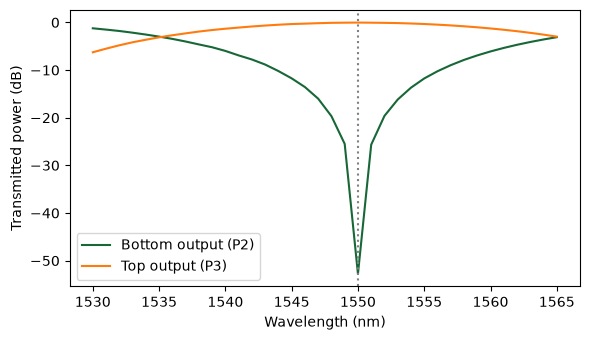

In [15]:
# Scattering matrix of the MZI from its parts
s_mzi = device.s_matrix(frequencies)

# Power in the two MZI outputs for light entering P0
p_bottom = np.abs(s_mzi["P0@0", "P2@0"]) ** 2
p_top = np.abs(s_mzi["P0@0", "P3@0"]) ** 2

# Extinction ratio at 1550 nm: bright output over dark output (dB)
bright = max(p_bottom[i_1550], p_top[i_1550])
dark = min(p_bottom[i_1550], p_top[i_1550])
extinction = 10 * np.log10(bright / dark)

# Phase difference between the arms at 1550 nm, in units of 2π
phase_cycles = n_eff * delta_length / 1.550
print(f"Arm phase difference at 1550 nm: {phase_cycles:.3f} × 2π")
print(f"Extinction ratio at 1550 nm: {extinction:.1f} dB")

fig, ax = plt.subplots(figsize=(6, 3.5), tight_layout=True)

# MZI outputs across the band in dB
ax.plot(wavelengths * 1e3, 10 * np.log10(p_bottom), label="Bottom output (P2)")
ax.plot(wavelengths * 1e3, 10 * np.log10(p_top), label="Top output (P3)")
ax.axvline(1550, color="gray", linestyle=":")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Transmitted power (dB)")
ax.legend()
plt.show()

## Score

The score function checks the coupler and fabrication constraints. If all of them pass, the score is the MZI extinction ratio at 1550 nm in dB, capped at 40. A coupler that also stays within 50 ± 5 % across 1530 to 1565 nm earns a bonus of 5 points.

In [18]:
def mzi_score(split, min_feature, min_radius, extinction):
    # Pass or fail for every constraint of the challenge
    checks = {
        "Coupler split ratio at 1550 nm within 50 ± 1 %": abs(split[i_1550] - 50) <= 1,
        "Minimum gap or feature at least 100 nm": min_feature >= 0.1,
        "Minimum bend radius at least 5 μm": min_radius >= 5,
    }

    # Stretch goal: split ratio within 50 ± 5 % across the whole band
    stretch = bool(np.all(np.abs(split - 50) <= 5))

    # Print the outcome of each check
    for name, passed in checks.items():
        print(f"{'PASS' if passed else 'FAIL'}  {name}")
    print(
        f"{'PASS' if stretch else 'FAIL'}  Stretch: split ratio within 50 ± 5 % from 1530 to 1565 nm"
    )

    # Capped extinction ratio plus the stretch bonus if every constraint passes
    if not all(checks.values()):
        return 0.0
    return min(extinction, 40.0) + (5.0 if stretch else 0.0)


# Smallest drawn feature or gap and the tightest bend of the layout (μm)
min_feature = min(width, gap)
min_radius = min(s_bend_radius, arm_radius)

# Score of the current design
score = mzi_score(split, min_feature, min_radius, extinction)
print(f"\nScore: {score:.1f}")

PASS  Coupler split ratio at 1550 nm within 50 ± 1 %
PASS  Minimum gap or feature at least 100 nm
PASS  Minimum bend radius at least 5 μm
FAIL  Stretch: split ratio within 50 ± 5 % from 1530 to 1565 nm

Score: 40.0


## Where to go from here

- **Coupler first.** The split ratio is the only constraint the starting design fails. Use the coupling length estimate to get close before you run FDTD: the S-bends add coupling, so the straight section you need is shorter than $L_{50}$. Two or three FDTD runs at different coupling lengths are enough to interpolate to 50:50, since $P_{cross}$ follows $\sin^2$ of the total coupling.
- **Then the arms.** Choose $\Delta L$ so that the phase difference at 1550 nm is a whole number of $2\pi$ cycles, using $\Delta\varphi = 2\pi n_{eff} \Delta L / \lambda$ and the effective index printed above. Changing `delta_length` needs no new FDTD run, only the circuit calculation.
- **Stretch goal.** The split drifts across the band because $\Delta n / \lambda$ changes with wavelength. Compare that drift for different gaps and widths at their 50:50 coupling length; a coupler whose $\Delta n$ grows in step with $\lambda$ stays flat.
- **Budget.** Every new width, gap or coupling length costs one FDTD run. Print `cost` before running a sweep.

# Part II: Probabilistic CNOT gate

This part builds a post-selected linear-optical CNOT gate and simulates it with two photons.

**Encoding:** Each qubit is one photon in a pair of waveguides: control $|0\rangle$, $|1\rangle$ in `C0`, `C1` and target $|0\rangle$, $|1\rangle$ in `T0`, `T1`. Two more waveguides, `VC` and `VT`, have no input photon.

**Circuit:** $\mathrm{CNOT} = (I \otimes H)\,\mathrm{CZ}\,(I \otimes H)$. Built from five tunable MZIs. $R$ is the fraction of light that stays in its own waveguide.

| MZI | Waveguides | $R$ | Role |
|---|---|---|---|
| H1, H2 | T0, T1 | 1/2 | Hadamard on the target |
| CZ | C1, T0 | 1/3 | Two-photon interference that gives the controlled sign flip |
| Ac | VC, C0 | 1/3 | Gives C0 the same 1/3 transmission as C1 |
| At | T1, VT | 1/3 | Gives T1 the same 1/3 transmission as T0 |

Each MZI is two Part I couplers with a heater on one arm. More heaters on the qubit waveguides cancel the phases added by couplers that are not exactly 50:50.

**Post-selection:** The gate is correct only when one photon leaves in the control pair and one in the target pair. This happens with probability 1/9; all other events are discarded.

## Components

Straight waveguides are used and use PhotonForge's analytic waveguide model with the effective and group index from the Part I mode solve. A heater is a waveguide section under a metal strip. Its phase is related to dissipated power, $\varphi = \pi (V / V_\pi)^2$.

In [ ]:
heater_length = 100.0  # Heater length (μm)
heater_v_pi = 5.0  # Heater voltage for a π phase shift (V): assumed 25 mW into 1 kΩ
waveguide_loss = 2e-4  # Waveguide propagation loss (dB/μm): assumed 2 dB/cm

# define waveguide model
waveguide_model = pf.AnalyticWaveguideModel(
    n_eff=n_eff,
    n_group=n_group,
    reference_frequency=pf.C_0 / 1.550,
    propagation_loss=waveguide_loss,
    k2=np.pi / (heater_v_pi**2 * heater_length),
)

# normal straight waveguide
def straight_waveguide(length, name):
    return pf.parametric.straight(
        port_spec="Strip", length=length, model=waveguide_model, name=name
    )

# heater: waveguide under a metal strip
def heater(label):
    section = straight_waveguide(heater_length, f"HEATER_{label}")
    section.add(
        "METAL", pf.Rectangle(center=(heater_length / 2, 0), size=(heater_length, 2))
    )
    return section

# unheated section with the same length and model as a heater
plain_section = straight_waveguide(heater_length, "PLAIN")

# Two couplers from part I joined by equal arms, with the heater on the upper arm
def tunable_mzi(label):
    component = pf.Component(f"MZI_{label}")
    splitter = component.add_reference(coupler)
    lower_arm = component.add_reference(plain_section).connect("P0", splitter["P2"])
    component.add_reference(heater(label)).connect("P0", splitter["P3"])
    combiner = component.add_reference(coupler).connect("P0", lower_arm["P1"])
    component.add_port([splitter["P0"], splitter["P1"], combiner["P2"], combiner["P3"]])
    component.add_model(pf.CircuitModel(), "Circuit")
    return component

## Chip layout

The six waveguides are spaced like the coupler ports so every element joins its neighbors without bends. Waveguides that skip an MZI column get a straight section of the same length. Heater columns sit before H1, before H2 and at the output. Ports `*_IN` and `*_OUT` are the chip facets, where the photons enter and the detectors sit.

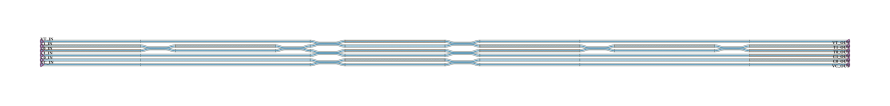

In [ ]:
# waveguides from bottom to top
rails = ["VC", "C0", "C1", "T0", "T1", "VT"]
pitch = coupler.ports["P1"].center[1] - coupler.ports["P0"].center[1]
coupler_length = coupler.ports["P2"].center[0] - coupler.ports["P0"].center[0]
mzi_length = 2 * coupler_length + heater_length

# circuit stages from input to output
stages = [
    ("heaters", {"T0": "T0_IN", "T1": "T1_IN"}),
    ("mzis", {"T0": "H1"}),
    ("mzis", {"VC": "Ac", "C1": "CZ", "T1": "At"}),
    ("heaters", {"T0": "T0_MID", "T1": "T1_MID"}),
    ("mzis", {"T0": "H2"}),
    ("heaters", {"C0": "C0_OUT", "C1": "C1_OUT", "T0": "T0_OUT", "T1": "T1_OUT"}),
]
heater_labels = [label for _, labels in stages for label in labels.values()]
bypass = straight_waveguide(mzi_length, "BYPASS")

chip = pf.Component("CNOT_CHIP")
mzis = {}
first_ports, last_ports = {}, {}
x_stage = 0.0
for kind, labels in stages:
    k = 0
    while k < len(rails):
        label = labels.get(rails[k])
        if kind == "mzis" and label:
            mzis[label] = tunable_mzi(label)
            ref = chip.add_reference(mzis[label]).translate((x_stage, k * pitch))
            joints = [(rails[k], "P0", "P2"), (rails[k + 1], "P1", "P3")]
        else:
            if kind == "mzis":
                section = bypass
            else:
                section = heater(label) if label else plain_section
            ref = chip.add_reference(section).translate((x_stage, k * pitch))
            joints = [(rails[k], "P0", "P1")]
        for rail, port_in, port_out in joints:
            first_ports.setdefault(rail, ref[port_in])
            last_ports[rail] = ref[port_out]
        k += len(joints)
    x_stage += mzi_length if kind == "mzis" else heater_length

for rail in rails:
    chip.add_port(first_ports[rail], f"{rail}_IN")
for rail in rails:
    chip.add_port(last_ports[rail], f"{rail}_OUT")
chip.add_model(pf.CircuitModel(), "Circuit")

connections = chip.get_netlist()["connections"]
assert len(connections) == 5 * len(rails), "Disconnected waveguides"
viewer(chip)

## Heater calibration

With balanced arms and heater phase $\theta$, an MZI made of a coupler with through and cross amplitudes $t$ and $c$ has the bar fraction

$$R(\theta) = \frac{|t^2 + c^2 e^{i\theta}|^2}{|t^2 + c^2 e^{i\theta}|^2 + |t c\,(1 + e^{i\theta})|^2}.$$

Using $t$ and $c$ from Part I, this cell calculates for $R = 1/2$ and $R = 1/3$. It then simulates one MZI at each setting with PhotonForge to test the calibration for $R$.

In [24]:
# calculate heater voltage for a given phase shift
def phase_voltage(phase):
    return heater_v_pi * np.sqrt(np.mod(phase, 2 * np.pi) / np.pi)

# through and cross amplitudes of the coupler from Part I
t_dc = s_coupler["P0@0", "P2@0"][i_1550]
c_dc = s_coupler["P0@0", "P3@0"][i_1550]

# MZI bar fraction against heater phase, on the branch from the cross to the bar state
theta_grid = np.linspace(-np.pi / 2, 3 * np.pi / 2, 8001)
bar_amp = t_dc**2 + c_dc**2 * np.exp(1j * theta_grid)
cross_amp = t_dc * c_dc * (1 + np.exp(1j * theta_grid))
bar_grid = np.abs(bar_amp) ** 2 / (np.abs(bar_amp) ** 2 + np.abs(cross_amp) ** 2)
rising = slice(np.argmin(bar_grid), np.argmax(bar_grid) + 1)

# heater voltage that gives the MZI bar fraction
def mzi_heater_voltage(bar):
    if not bar_grid.min() < bar < bar_grid.max():
        raise ValueError(
            f"An MZI of this coupler (split {split[i_1550]:.1f} %) cannot reach "
            f"R = {bar:.3f}; R = 1/3 needs a split between about 21 % and 79 %"
        )
    return phase_voltage(np.interp(bar, bar_grid[rising], theta_grid[rising]))

# circuit updates that set the voltage of each heater
def heater_updates(heater_voltages):
    unknown = set(heater_voltages) - set(heater_labels)
    assert not unknown, f"Unknown heaters: {unknown}"
    return {
        (None, f"HEATER_{label}$"): {"model_updates": {"voltage": voltage}}
        for label, voltage in heater_voltages.items()
    }

# 2x2 transfer matrix at 1550 nm
def mzi_transfer(label, voltage):
    s = mzis[label].s_matrix(
        frequencies,
        show_progress=False,
        model_kwargs={"updates": heater_updates({label: voltage})},
    )
    return np.array([[s[f"P{i}@0", f"P{o}@0"][i_1550] for i in (0, 1)] for o in (2, 3)])


voltages = {label: mzi_heater_voltage(1 / 2) for label in ("H1", "H2")}
voltages.update({label: mzi_heater_voltage(1 / 3) for label in ("Ac", "CZ", "At")})
t_half = mzi_transfer("H1", voltages["H1"])
t_third = mzi_transfer("CZ", voltages["CZ"])
for setting, t in (("1/2", t_half), ("1/3", t_third)):
    bar = abs(t[0, 0]) ** 2 / (abs(t[0, 0]) ** 2 + abs(t[1, 0]) ** 2)
    print(f"R = {setting}: simulated R = {bar:.4f}")

gamma_in = np.angle(t_half[0, 1] / t_half[0, 0])
gamma_out = np.angle(t_half[1, 0] / t_half[0, 0])

(a, x), (y, d) = t_third
alpha = np.angle(a / d)
beta = np.angle((a * d + x * y) / d**2)

def phase_pair(lower, upper, phase):
    phase = np.angle(np.exp(1j * phase))
    return {lower: phase_voltage(max(-phase, 0)), upper: phase_voltage(max(phase, 0))}


voltages.update(phase_pair("T0_IN", "T1_IN", -gamma_in))
voltages.update(phase_pair("T0_MID", "T1_MID", -(gamma_out + alpha + gamma_in)))
voltages.update(phase_pair("C0_OUT", "C1_OUT", -beta))
voltages.update(phase_pair("T0_OUT", "T1_OUT", -gamma_out))

R = 1/2: simulated R = 0.5013
R = 1/3: simulated R = 0.3348


## Two-photon simulation

Using the heater voltages, PhotonForge computes the S matrix of the whole chip. Its block $U$ from the six inputs to the six outputs transforms each photon's creation operator, $a_i^\dagger \to \sum_k U_{ki}\, a_k^\dagger$. For indistinguishable photons entering waveguides $i$ and $j$, the amplitude to detect one in $k$ and one in $l \neq k$ is the permanent $U_{ki} U_{lj} + U_{li} U_{kj}$.

Process fidelity (1550 nm): 1.0000
Success probability (1550 nm): |00⟩ 0.1006, |01⟩ 0.0999, |10⟩ 0.1005, |11⟩ 0.1003
Process fidelity (1530 to 1565 nm) 0.9559 to 1.0000, average success 0.0992 to 0.1029


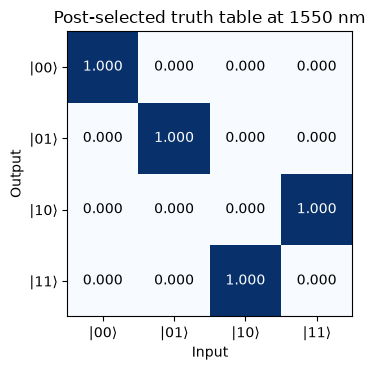

In [26]:
s_chip = chip.s_matrix(
    frequencies, show_progress=False, model_kwargs={"updates": heater_updates(voltages)}
)

# transfer matrices between the six waveguides
U = np.array(
    [[s_chip[f"{i}_IN@0", f"{o}_OUT@0"] for i in rails] for o in rails]
).transpose(2, 0, 1)

control, target = (1, 2), (3, 4)  # indices of C0, C1 and T0, T1

# waveguides of the two photons in the logical states |00>, |01>, |10>, |11>
logical = [(c, t) for c in control for t in target]
basis = ["|00⟩", "|01⟩", "|10⟩", "|11⟩"]
cnot = np.eye(4)[[0, 1, 3, 2]]


def gate_matrix(u):
    # post-selected gate in the logical basis
    return np.array(
        [
            [u[k, i] * u[l, j] + u[l, i] * u[k, j] for i, j in logical]
            for k, l in logical
        ]
    )


gates = np.array([gate_matrix(u) for u in U])
success = np.sum(np.abs(gates) ** 2, axis=1)  # coincidence probability for each input
fidelity = np.abs(np.einsum("ij,wij->w", cnot, gates)) ** 2 / (4 * success.sum(axis=1))

print(f"Process fidelity (1550 nm): {fidelity[i_1550]:.4f}")
print(
    "Success probability (1550 nm): "
    + ", ".join(f"{b} {p:.4f}" for b, p in zip(basis, success[i_1550]))
)
print(
    f"Process fidelity (1530 to 1565 nm) {fidelity.min():.4f} to "
    f"{fidelity.max():.4f}, average success {success.mean(axis=1).min():.4f} to "
    f"{success.mean(axis=1).max():.4f}"
)

# truth table: output probabilities given a coincidence
truth = np.abs(gates[i_1550]) ** 2 / success[i_1550]
fig, ax = plt.subplots(figsize=(4.5, 3.8), tight_layout=True)
ax.imshow(truth, cmap="Blues", vmin=0, vmax=1)
for (row, col), value in np.ndenumerate(truth):
    color = "white" if value > 0.5 else "black"
    ax.text(col, row, f"{value:.3f}", ha="center", va="center", color=color)
ax.set_xticks(range(4), basis)
ax.set_yticks(range(4), basis)
ax.set_xlabel("Input")
ax.set_ylabel("Output")
ax.set_title("Post-selected truth table at 1550 nm")
plt.show()

## Post-selection

Each output is fed into a single-photon detector. A run is kept only when one detector in the control pair and one in the target pair click; every other event is discarded.

In [28]:
rng = np.random.default_rng(2026)
pairs_per_input = 20_000

# Detector pairs that can click (k = l: both photons in the same waveguide)
patterns = [(k, l) for k in range(6) for l in range(k, 6)]


def classify(k, l):
    if k in control and l in target:
        return "kept"
    if {k, l} & {0, 5}:
        return "vacuum port"
    return "both in control pair" if k in control else "both in target pair"


u = U[i_1550]
counts = np.zeros((4, 4), dtype=int)
print(f"{pairs_per_input:,} photon pairs per input (1550 nm)")
for n, (i, j) in enumerate(logical):
    p = np.array(
        [
            abs(u[k, i] * u[l, j] + u[l, i] * u[k, j]) ** 2 / (2 if k == l else 1)
            for k, l in patterns
        ]
    )
    p = np.append(p, max(0.0, 1 - p.sum()))  # Last entry: a photon is lost
    draws = np.bincount(
        rng.choice(p.size, pairs_per_input, p=p / p.sum()), minlength=p.size
    )
    flags = {"vacuum port": 0, "both in control pair": 0, "both in target pair": 0}
    for (k, l), count in zip(patterns, draws):
        result = classify(k, l)
        if result == "kept":
            counts[logical.index((k, l)), n] += count
        else:
            flags[result] += count
    flags["photon lost"] = draws[-1]
    kept = counts[:, n].sum()
    print(
        f"Input {basis[n]}: kept {kept:,} ({kept / pairs_per_input:.1%}) | outputs "
        + ", ".join(f"{b} {c:,}" for b, c in zip(basis, counts[:, n]))
    )

20,000 photon pairs per input (1550 nm)
Input |00⟩: kept 2,009 (10.0%) | outputs |00⟩ 2,009, |01⟩ 0, |10⟩ 0, |11⟩ 0
Input |01⟩: kept 1,937 (9.7%) | outputs |00⟩ 0, |01⟩ 1,937, |10⟩ 0, |11⟩ 0
Input |10⟩: kept 2,025 (10.1%) | outputs |00⟩ 0, |01⟩ 0, |10⟩ 0, |11⟩ 2,025
Input |11⟩: kept 2,009 (10.0%) | outputs |00⟩ 0, |01⟩ 0, |10⟩ 2,009, |11⟩ 0
